# Experimento 14 — Seleção individual com busca independente de cinco trials

Cinco configurações sorteadas por categoria, avaliadas em cada subconjunto de features.
Nenhum vencedor do Exp. 13 é utilizado para formar o catálogo; só seus pesos e protocolo.
A configuração mantém parâmetros/seed nos três anos, com um novo ajuste por corte.

A análise individual mostra efeitos com a configuração fixa e também o melhor trial por
remoção. Na eliminação progressiva há **uma trajetória por categoria**: a cada subconjunto,
os cinco trials concorrem novamente e o vencedor pode mudar. O RMSE ponderado seleciona.
O Top 5 final é de pares configuração + features válidos, com quantidade e lista de features por categoria.

Os anos usados na seleção não são teste independente. Os resultados anteriores ficam
preservados. [Detalhes](../../docs/exp14_busca_independente.md).

In [1]:
from pathlib import Path
import sys
from html import escape
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

atual=Path.cwd().resolve()
raiz=next(p for p in [atual,*atual.parents] if (p/'raw_data').is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0,str(raiz))
from src import exp11 as comum, exp14_busca as exp

SEED=42
ANOS=[2023,2024,2025]
FEATURES=list(exp.FEATURES)
ORIGEM=raiz/'checkpoints'/'exp13'
CHECKPOINTS=raiz/'checkpoints'/'exp14'/'busca_independente'
SUBMISSIONS=raiz/'submissions'/'exp14_busca_independente'
N_TRIALS=5
TOP_K=5
RODAR_PILOTO=True
RODAR_ANALISE_COMPLETA=True
RODAR_PROGRESSIVA=True
GERAR_SUBMISSIONS=True
PILOTO_FEATURES=['RecentWinRate10Diff','RecentAvgMargin10Diff']
PILOTO_CONFIGURACOES_POR_CATEGORIA=1
MAX_AVALIACOES_POR_CONFIGURACAO=100  # Subconjuntos únicos, cada um com três cortes; controle excluído.
MAX_FEATURES_REMOVIDAS=10
MIN_FEATURES=5
MELHORA_MINIMA_RMSE=.001
REPETIR_FALHAS=False
MOSTRAR_LOG_AVALIACOES=False
assert len(FEATURES)==26
display(comum.versoes())


{'h2o': '3.46.0.12',
 'tabpfn': '9.2.0',
 'torch': '2.11.0+cu128',
 'numpy': '2.2.6',
 'pandas': '2.3.2',
 'scikit-learn': '1.7.1',
 'psutil': '7.2.2'}

## Catálogo independente

Cinco configurações sorteadas, sem consultar rankings do Exp. 13, no mesmo espaço de
parâmetros do Exp. 15. É busca aleatória reproduzível, não Optuna adaptativo. Os mesmos
cinco trials são comparados nos diferentes subconjuntos para manter a comparabilidade,
mas cada subconjunto/categoria escolhe seu próprio vencedor. Quantidades e listas
de features aparecem nas tabelas e nos detalhes dos Tops.

In [2]:
def mostrar_top(tabela,titulo):
    display(Markdown('### '+titulo))
    if tabela.empty:
        print('Nenhuma combinação com os três anos válidos ainda.'); return
    for cat,nome in [('M','Masculino'),('W','Feminino')]:
        top=tabela.loc[tabela.Categoria.eq(cat)&tabela.Posicao.le(TOP_K)].sort_values('Posicao')
        display(Markdown('**'+nome+' ('+cat+')**'))
        if top.empty:
            print('Sem combinações completas.'); continue
        colunas=['Posicao','Configuracao','NFeatures','NRemovidas','RMSE_pond','LB_pond',
                 'Delta_RMSE_pond','Delta_LB_pond']
        display(top[[c for c in colunas if c in top]].reset_index(drop=True))
        for r in top.to_dict('records'):
            mantidas=', '.join(r['Features'])
            removidas=', '.join(r.get('Removidas',[])) or 'Nenhuma'
            display(HTML('<details><summary>'+escape(f"Top {r['Posicao']} — {r['NFeatures']} features — {r['Configuracao']}")+
                '</summary><p><strong>Mantidas:</strong> '+escape(mantidas)+
                '</p><p><strong>Removidas:</strong> '+escape(removidas)+'</p></details>'))

def salvar_tabela(nome,tabela):
    registros=tabela.astype(object).where(tabela.notna(),None).to_dict('records')
    comum.salvar_json(CHECKPOINTS/nome,registros)

manifesto=exp.carregar_busca(ORIGEM,n_trials=N_TRIALS,seed=SEED)
catalogo=manifesto['candidatos']
REFERENCIAS=manifesto['referencias']
catalogo_tabela=pd.DataFrame(catalogo)
catalogo_tabela['Trial']=catalogo_tabela.groupby('Categoria').cumcount()+1
catalogo_tabela['n_estimators']=catalogo_tabela.Parametros.map(lambda p:p['n_estimators'])
assert len(catalogo)==2*N_TRIALS
display(catalogo_tabela[['Categoria','Trial','Candidato','Familia','n_estimators','Perfil','Parametros']],REFERENCIAS)
comum.salvar_json(CHECKPOINTS/'catalogo_busca.json',{**manifesto,'referencias':REFERENCIAS.to_dict('records')})

,Categoria,Trial,Candidato,Familia,n_estimators,Perfil,Parametros
0,M,1,M_tabpfn12_06feabfa5be15ec3,V3_5_FAST,32,alvo_identidade,"{'version': 'V3_5_FAST', 'n_estimators': 32, '..."
1,M,2,M_tabpfn12_95beaf425161d405,V3_5_FAST,4,alvo_safepower,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
2,M,3,M_tabpfn12_36abdf9dabab40fa,V3_5_FAST,8,padrao,"{'version': 'V3_5_FAST', 'n_estimators': 8, 'r..."
3,M,4,M_tabpfn12_0e7f98e147911e84,V3_5_FAST,64,colunas_rotate,"{'version': 'V3_5_FAST', 'n_estimators': 64, '..."
4,M,5,M_tabpfn12_2d0fbd793d895194,V3_5,8,colunas_rotate,"{'version': 'V3_5', 'n_estimators': 8, 'random..."
5,W,1,W_tabpfn12_06feabfa5be15ec3,V3_5_FAST,32,alvo_identidade,"{'version': 'V3_5_FAST', 'n_estimators': 32, '..."
6,W,2,W_tabpfn12_95beaf425161d405,V3_5_FAST,4,alvo_safepower,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
7,W,3,W_tabpfn12_36abdf9dabab40fa,V3_5_FAST,8,padrao,"{'version': 'V3_5_FAST', 'n_estimators': 8, 'r..."
8,W,4,W_tabpfn12_0e7f98e147911e84,V3_5_FAST,64,colunas_rotate,"{'version': 'V3_5_FAST', 'n_estimators': 64, '..."
9,W,5,W_tabpfn12_2d0fbd793d895194,V3_5,8,colunas_rotate,"{'version': 'V3_5', 'n_estimators': 8, 'random..."


,Season,Distancia,Peso
0,2025,7.624698,0.374675
1,2024,8.193139,0.348680
2,2023,10.326554,0.276645


## Preparação e controle equivalente

O mesmo preparo do Exp. 13: todas as features são pré-NCAA e diferenças A − B.
M: 2003+, W: 2010+; 2026: DayNum < 134. O controle só é importado se configuração,
dados, features, versões e protocolo forem equivalentes. Esta célula não treina;
controles ausentes serão ajustados apenas quando uma etapa habilitada precisar deles.


In [3]:
preparacao=exp.preparar_dados(raiz/'raw_data')
jogos=preparacao['jogos']
confrontos,sample=preparacao['confrontos'],preparacao['sample']
display(preparacao['auditoria'])
for cat,tabela in jogos.items():
    assert tabela.TeamA.lt(tabela.TeamB).all()
    np.testing.assert_allclose(tabela.Target,tabela.ScoreA-tabela.ScoreB)
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
    display(pd.DataFrame({'Categoria':cat,'NaN':tabela[FEATURES].isna().sum(),
        'Inf':np.isinf(tabela[FEATURES].to_numpy()).sum(axis=0)},index=FEATURES))

avaliador=exp.Avaliador(jogos,catalogo,REFERENCIAS,pasta=CHECKPOINTS,pasta_exp13=ORIGEM,
    max_avaliacoes_por_configuracao=MAX_AVALIACOES_POR_CONFIGURACAO,repetir_falhas=REPETIR_FALHAS,
    verbose=MOSTRAR_LOG_AVALIACOES)
auditoria_controle=avaliador.auditar_controle()
display(auditoria_controle.groupby(['Categoria','Status']).size().rename('Cortes'))
controles_reutilizados=avaliador.reutilizar_controles()
print('Configurações com controle completo reutilizado sem fit:',len(controles_reutilizados),f'/ {2*N_TRIALS}')
salvar_tabela('auditoria_controle.json',auditoria_controle)


,Categoria,JogosTreinoHistorico,PrimeiroAno,UltimoAno,FontesFeatures,Limite2026,SemSobreposicaoNCAA,JogosDetalhados2026,UltimoDayNum2026
0,M,1449,2003,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5647,132
1,W,961,2010,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5479,132


,Categoria,NaN,Inf
SeedDif,M,0,0
WinRateDiff,M,0,0
AvgPointsForDiff,M,0,0
AvgPointsAgainstDiff,M,0,0
OppWinRateDiff,M,0,0
FGPercentageDiff,M,0,0
ThreePointPercentageDiff,M,0,0
FTPercentageDiff,M,0,0
AssistsPerGameDiff,M,0,0
OffensiveReboundsPerGameDiff,M,0,0


,Categoria,NaN,Inf
SeedDif,W,0,0
WinRateDiff,W,0,0
AvgPointsForDiff,W,0,0
AvgPointsAgainstDiff,W,0,0
OppWinRateDiff,W,0,0
FGPercentageDiff,W,0,0
ThreePointPercentageDiff,W,0,0
FTPercentageDiff,W,0,0
AssistsPerGameDiff,W,0,0
OffensiveReboundsPerGameDiff,W,0,0


Categoria  Status       
M          compativel_ok    15
W          compativel_ok    15
Name: Cortes, dtype: int64

Configurações com controle completo reutilizado sem fit: 10 / 10


In [4]:
if RODAR_PILOTO or RODAR_ANALISE_COMPLETA or RODAR_PROGRESSIVA or GERAR_SUBMISSIONS:
    ambiente=comum.detectar_tabpfn(exigir_gpu=True)
    comum.carregar_token_tabpfn(raiz/'.env.tabpfn')
    display(comum.validar_acesso_tabpfn(),ambiente)
    comum.salvar_json(CHECKPOINTS/'ambiente.json',{'tabpfn':ambiente,'versoes':comum.versoes()})

if RODAR_PILOTO:
    assert 1<=PILOTO_CONFIGURACOES_POR_CATEGORIA<=N_TRIALS
    ids_piloto=catalogo_tabela.loc[catalogo_tabela.Trial.le(PILOTO_CONFIGURACOES_POR_CATEGORIA),'Candidato'].tolist()
    piloto=exp.avaliar_individuais(avaliador,features=PILOTO_FEATURES,configuracoes=ids_piloto,piloto=True)
    display(piloto.drop(columns='Features'))
    salvar_tabela('piloto.json',piloto)
else:
    print('Piloto desativado.')
display(avaliador.contagem())


{'chave_valida': True,
 'licenca': 'tabpfn-3-5-license-v1.0',
 'licenca_aceita': True}

{'device': 'cuda:0',
 'cuda': '12.8',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'vram_gb': 11.99951171875,
 'versoes': {'h2o': '3.46.0.12',
  'tabpfn': '9.2.0',
  'torch': '2.11.0+cu128',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scikit-learn': '1.7.1',
  'psutil': '7.2.2'}}

,Categoria,Configuracao,FeatureRemovida,Avaliacao,NFeatures,status,RMSE_controle,RMSE_sem,LB_controle,LB_sem,Delta_RMSE,Delta_LB,Impacto,PosicaoImpacto
0,M,M_tabpfn12_06feabfa5be15ec3,RecentAvgMargin10Diff,M_tabpfn12_06feabfa5be15ec3__f01f0c6011d329a50,25,ok,12.133602,12.130397,0.073620,0.073809,-0.003206,0.000189,melhorou,1
1,M,M_tabpfn12_06feabfa5be15ec3,RecentWinRate10Diff,M_tabpfn12_06feabfa5be15ec3__f60fb92879c3cfbe2,25,ok,12.133602,12.136788,0.073620,0.074140,0.003186,0.000520,piorou,2
2,W,W_tabpfn12_06feabfa5be15ec3,RecentAvgMargin10Diff,W_tabpfn12_06feabfa5be15ec3__f01f0c6011d329a50,25,ok,12.403656,12.410759,0.050553,0.050551,0.007103,-0.000002,piorou,1
3,W,W_tabpfn12_06feabfa5be15ec3,RecentWinRate10Diff,W_tabpfn12_06feabfa5be15ec3__f60fb92879c3cfbe2,25,ok,12.403656,12.453841,0.050553,0.050571,0.050185,0.000018,piorou,2


,Categoria,Configuracao,AvaliacoesUsadas,Limite
0,M,M_tabpfn12_06feabfa5be15ec3,2,100
1,M,M_tabpfn12_95beaf425161d405,0,100
2,M,M_tabpfn12_36abdf9dabab40fa,0,100
3,M,M_tabpfn12_0e7f98e147911e84,0,100
4,M,M_tabpfn12_2d0fbd793d895194,0,100
5,W,W_tabpfn12_06feabfa5be15ec3,2,100
6,W,W_tabpfn12_95beaf425161d405,0,100
7,W,W_tabpfn12_36abdf9dabab40fa,0,100
8,W,W_tabpfn12_0e7f98e147911e84,0,100
9,W,W_tabpfn12_2d0fbd793d895194,0,100


## Etapa A — Remoção individual

Habilite RODAR_ANALISE_COMPLETA=True para as 26 remoções em cada configuração.
São 260 pares subconjunto/trial / 780 ajustes históricos, aproveitando o piloto.
Cada teste recomeça com as 26 features e remove **somente uma**; a importância
é específica da configuração. Delta negativo indica que remover melhorou o RMSE.


,Categoria,FeatureRemovida,NFeatures,status,TrialsValidos,TrialsPrevistos,Configuracao,ConfiguracaoControle,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,MudouConfiguracao
0,M,AssistsPerGameDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.086968,-0.027744,0.073605,0.073129,False
1,M,FGPercentageDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.087523,-0.027190,0.073605,0.073249,False
2,M,StealsPerGameDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.087983,-0.026729,0.073605,0.072873,False
3,M,DefensiveRatingDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.093623,-0.021089,0.073605,0.073415,False
4,M,OppWinRateDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.094238,-0.020474,0.073605,0.074111,False
5,M,OffensiveReboundsPerGameDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.096310,-0.018402,0.073605,0.073536,False
6,M,TurnoverRateDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.099130,-0.015583,0.073605,0.073473,False
7,M,FreeThrowRateDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.100879,-0.013834,0.073605,0.073479,False
8,M,DefensiveReboundsPerGameDiff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.101821,-0.012891,0.073605,0.073357,False
9,M,RecentAvgPointsFor10Diff,25,ok,5,5,M_tabpfn12_36abdf9dabab40fa,M_tabpfn12_36abdf9dabab40fa,12.114713,12.102162,-0.012551,0.073605,0.073616,False


Testes  Melhoraram
Categoria Configuracao                                   
M         M_tabpfn12_06feabfa5be15ec3      26          13
          M_tabpfn12_0e7f98e147911e84      26          11
          M_tabpfn12_2d0fbd793d895194      26          11
          M_tabpfn12_36abdf9dabab40fa      26          14
          M_tabpfn12_95beaf425161d405      26           7
W         W_tabpfn12_06feabfa5be15ec3      26          14
          W_tabpfn12_0e7f98e147911e84      26          15
          W_tabpfn12_2d0fbd793d895194      26          10
          W_tabpfn12_36abdf9dabab40fa      26          16
          W_tabpfn12_95beaf425161d405      26          18

PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,StealsPerGameDiff,25,12.133602,12.103242,-0.030360,0.07362,0.072839,-0.000781,melhorou,ok
2,DefensiveRatingDiff,25,12.133602,12.113118,-0.020485,0.07362,0.073445,-0.000175,melhorou,ok
3,OppWinRateDiff,25,12.133602,12.118945,-0.014658,0.07362,0.074133,0.000513,melhorou,ok
4,FreeThrowRateDiff,25,12.133602,12.119436,-0.014166,0.07362,0.073501,-0.000119,melhorou,ok
5,AssistsPerGameDiff,25,12.133602,12.119945,-0.013657,0.07362,0.073331,-0.000289,melhorou,ok
6,OffensiveReboundsPerGameDiff,25,12.133602,12.121349,-0.012253,0.07362,0.073684,0.000063,melhorou,ok
7,TurnoverRateDiff,25,12.133602,12.121429,-0.012173,0.07362,0.073493,-0.000127,melhorou,ok
8,DefensiveReboundsPerGameDiff,25,12.133602,12.126269,-0.007334,0.07362,0.073462,-0.000158,melhorou,ok
9,EffectiveFGPercentageDiff,25,12.133602,12.126789,-0.006813,0.07362,0.073413,-0.000207,melhorou,ok
10,FGPercentageDiff,25,12.133602,12.126929,-0.006674,0.07362,0.073499,-0.000121,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,OppWinRateDiff,25,12.136775,12.117145,-0.019630,0.073451,0.073800,0.000349,melhorou,ok
2,StealsPerGameDiff,25,12.136775,12.118936,-0.017839,0.073451,0.072825,-0.000625,melhorou,ok
3,OffensiveReboundsPerGameDiff,25,12.136775,12.121120,-0.015655,0.073451,0.073502,0.000051,melhorou,ok
4,AssistsPerGameDiff,25,12.136775,12.121205,-0.015570,0.073451,0.073250,-0.000201,melhorou,ok
5,DefensiveRatingDiff,25,12.136775,12.122866,-0.013909,0.073451,0.073459,0.000008,melhorou,ok
6,TurnoverRateDiff,25,12.136775,12.127436,-0.009339,0.073451,0.073535,0.000084,melhorou,ok
7,FreeThrowRateDiff,25,12.136775,12.131318,-0.005457,0.073451,0.073665,0.000214,melhorou,ok
8,FGPercentageDiff,25,12.136775,12.132663,-0.004112,0.073451,0.073372,-0.000079,melhorou,ok
9,OffensiveRatingDiff,25,12.136775,12.132746,-0.004029,0.073451,0.073535,0.000084,melhorou,ok
10,WinRateDiff,25,12.136775,12.135515,-0.001260,0.073451,0.073822,0.000371,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,StealsPerGameDiff,25,12.169102,12.134965,-0.034137,0.073107,0.072363,-0.000744,melhorou,ok
2,TurnoverRateDiff,25,12.169102,12.140057,-0.029045,0.073107,0.072686,-0.000421,melhorou,ok
3,OppWinRateDiff,25,12.169102,12.143783,-0.025319,0.073107,0.073518,0.000411,melhorou,ok
4,DefensiveRatingDiff,25,12.169102,12.145170,-0.023932,0.073107,0.072806,-0.000301,melhorou,ok
5,EffectiveFGPercentageDiff,25,12.169102,12.146842,-0.022260,0.073107,0.072813,-0.000294,melhorou,ok
6,FreeThrowRateDiff,25,12.169102,12.153801,-0.015301,0.073107,0.072957,-0.000150,melhorou,ok
7,AssistsPerGameDiff,25,12.169102,12.154494,-0.014608,0.073107,0.072804,-0.000303,melhorou,ok
8,FGPercentageDiff,25,12.169102,12.155477,-0.013625,0.073107,0.072673,-0.000434,melhorou,ok
9,RecentAvgPointsFor10Diff,25,12.169102,12.163651,-0.005451,0.073107,0.073182,0.000075,melhorou,ok
10,DefensiveReboundsPerGameDiff,25,12.169102,12.167723,-0.001379,0.073107,0.073161,0.000054,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,AssistsPerGameDiff,25,12.114713,12.086968,-0.027744,0.073605,0.073129,-0.000476,melhorou,ok
2,FGPercentageDiff,25,12.114713,12.087523,-0.027190,0.073605,0.073249,-0.000356,melhorou,ok
3,StealsPerGameDiff,25,12.114713,12.087983,-0.026729,0.073605,0.072873,-0.000732,melhorou,ok
4,DefensiveRatingDiff,25,12.114713,12.093623,-0.021089,0.073605,0.073415,-0.000190,melhorou,ok
5,OppWinRateDiff,25,12.114713,12.094238,-0.020474,0.073605,0.074111,0.000506,melhorou,ok
6,OffensiveReboundsPerGameDiff,25,12.114713,12.096310,-0.018402,0.073605,0.073536,-0.000069,melhorou,ok
7,TurnoverRateDiff,25,12.114713,12.099130,-0.015583,0.073605,0.073473,-0.000132,melhorou,ok
8,FreeThrowRateDiff,25,12.114713,12.100879,-0.013834,0.073605,0.073479,-0.000126,melhorou,ok
9,DefensiveReboundsPerGameDiff,25,12.114713,12.101821,-0.012891,0.073605,0.073357,-0.000248,melhorou,ok
10,RecentAvgPointsFor10Diff,25,12.114713,12.102162,-0.012551,0.073605,0.073616,0.000011,melhorou,ok


... (2 outputs left out)

PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,FreeThrowRateDiff,25,12.396946,12.348401,-0.048545,0.050731,0.050426,-0.000305,melhorou,ok
2,BlocksPerGameDiff,25,12.396946,12.352192,-0.044754,0.050731,0.049703,-0.001028,melhorou,ok
3,AvgPointsAgainstDiff,25,12.396946,12.372619,-0.024327,0.050731,0.050572,-0.000158,melhorou,ok
4,TurnoverRateDiff,25,12.396946,12.378248,-0.018698,0.050731,0.050393,-0.000338,melhorou,ok
5,AvgPointsForDiff,25,12.396946,12.379482,-0.017463,0.050731,0.050298,-0.000433,melhorou,ok
6,DefensiveReboundsPerGameDiff,25,12.396946,12.379834,-0.017112,0.050731,0.050008,-0.000723,melhorou,ok
7,FGPercentageDiff,25,12.396946,12.380762,-0.016183,0.050731,0.050406,-0.000325,melhorou,ok
8,RecentAvgPointsAgainst10Diff,25,12.396946,12.381044,-0.015901,0.050731,0.050442,-0.000288,melhorou,ok
9,DefensiveRatingDiff,25,12.396946,12.383978,-0.012967,0.050731,0.050446,-0.000284,melhorou,ok
10,NetRatingDiff,25,12.396946,12.386362,-0.010583,0.050731,0.050471,-0.000260,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,BlocksPerGameDiff,25,12.390296,12.338493,-0.051804,0.050894,0.049900,-0.000994,melhorou,ok
2,FreeThrowRateDiff,25,12.390296,12.363204,-0.027093,0.050894,0.050579,-0.000315,melhorou,ok
3,AvgPointsForDiff,25,12.390296,12.368694,-0.021603,0.050894,0.050551,-0.000344,melhorou,ok
4,TurnoverRateDiff,25,12.390296,12.373461,-0.016835,0.050894,0.050442,-0.000452,melhorou,ok
5,AvgPointsAgainstDiff,25,12.390296,12.377476,-0.012821,0.050894,0.050678,-0.000217,melhorou,ok
6,TurnoversPerGameDiff,25,12.390296,12.378774,-0.011522,0.050894,0.050180,-0.000715,melhorou,ok
7,FGPercentageDiff,25,12.390296,12.381472,-0.008825,0.050894,0.050410,-0.000484,melhorou,ok
8,EffectiveFGPercentageDiff,25,12.390296,12.384033,-0.006264,0.050894,0.050428,-0.000467,melhorou,ok
9,DefensiveReboundsPerGameDiff,25,12.390296,12.384466,-0.005830,0.050894,0.050289,-0.000606,melhorou,ok
10,NetRatingDiff,25,12.390296,12.386284,-0.004012,0.050894,0.050615,-0.000279,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,BlocksPerGameDiff,25,12.409768,12.347646,-0.062122,0.050282,0.049352,-0.000930,melhorou,ok
2,FreeThrowRateDiff,25,12.409768,12.370592,-0.039176,0.050282,0.050084,-0.000198,melhorou,ok
3,DefensiveReboundsPerGameDiff,25,12.409768,12.374981,-0.034788,0.050282,0.049646,-0.000637,melhorou,ok
4,TurnoverRateDiff,25,12.409768,12.377725,-0.032044,0.050282,0.049976,-0.000306,melhorou,ok
5,TurnoversPerGameDiff,25,12.409768,12.381875,-0.027893,0.050282,0.049829,-0.000453,melhorou,ok
6,NetRatingDiff,25,12.409768,12.387431,-0.022337,0.050282,0.050258,-0.000024,melhorou,ok
7,DefensiveRatingDiff,25,12.409768,12.390058,-0.019710,0.050282,0.050246,-0.000036,melhorou,ok
8,ThreePointPercentageDiff,25,12.409768,12.391874,-0.017894,0.050282,0.050155,-0.000127,melhorou,ok
9,FGPercentageDiff,25,12.409768,12.392483,-0.017285,0.050282,0.050330,0.000048,melhorou,ok
10,EffectiveFGPercentageDiff,25,12.409768,12.393363,-0.016406,0.050282,0.049934,-0.000348,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,BlocksPerGameDiff,25,12.422099,12.345052,-0.077047,0.050541,0.049472,-0.001069,melhorou,ok
2,DefensiveReboundsPerGameDiff,25,12.422099,12.362565,-0.059534,0.050541,0.049604,-0.000937,melhorou,ok
3,TurnoversPerGameDiff,25,12.422099,12.374523,-0.047576,0.050541,0.049748,-0.000793,melhorou,ok
4,FGPercentageDiff,25,12.422099,12.380357,-0.041742,0.050541,0.050291,-0.000250,melhorou,ok
5,FreeThrowRateDiff,25,12.422099,12.383451,-0.038648,0.050541,0.050268,-0.000273,melhorou,ok
6,ThreePointPercentageDiff,25,12.422099,12.384126,-0.037973,0.050541,0.050161,-0.000380,melhorou,ok
7,TurnoverRateDiff,25,12.422099,12.386832,-0.035268,0.050541,0.050149,-0.000392,melhorou,ok
8,StealsPerGameDiff,25,12.422099,12.392985,-0.029114,0.050541,0.050265,-0.000276,melhorou,ok
9,AvgPointsAgainstDiff,25,12.422099,12.396544,-0.025555,0.050541,0.050718,0.000177,melhorou,ok
10,FTPercentageDiff,25,12.422099,12.396558,-0.025541,0.050541,0.050155,-0.000386,melhorou,ok


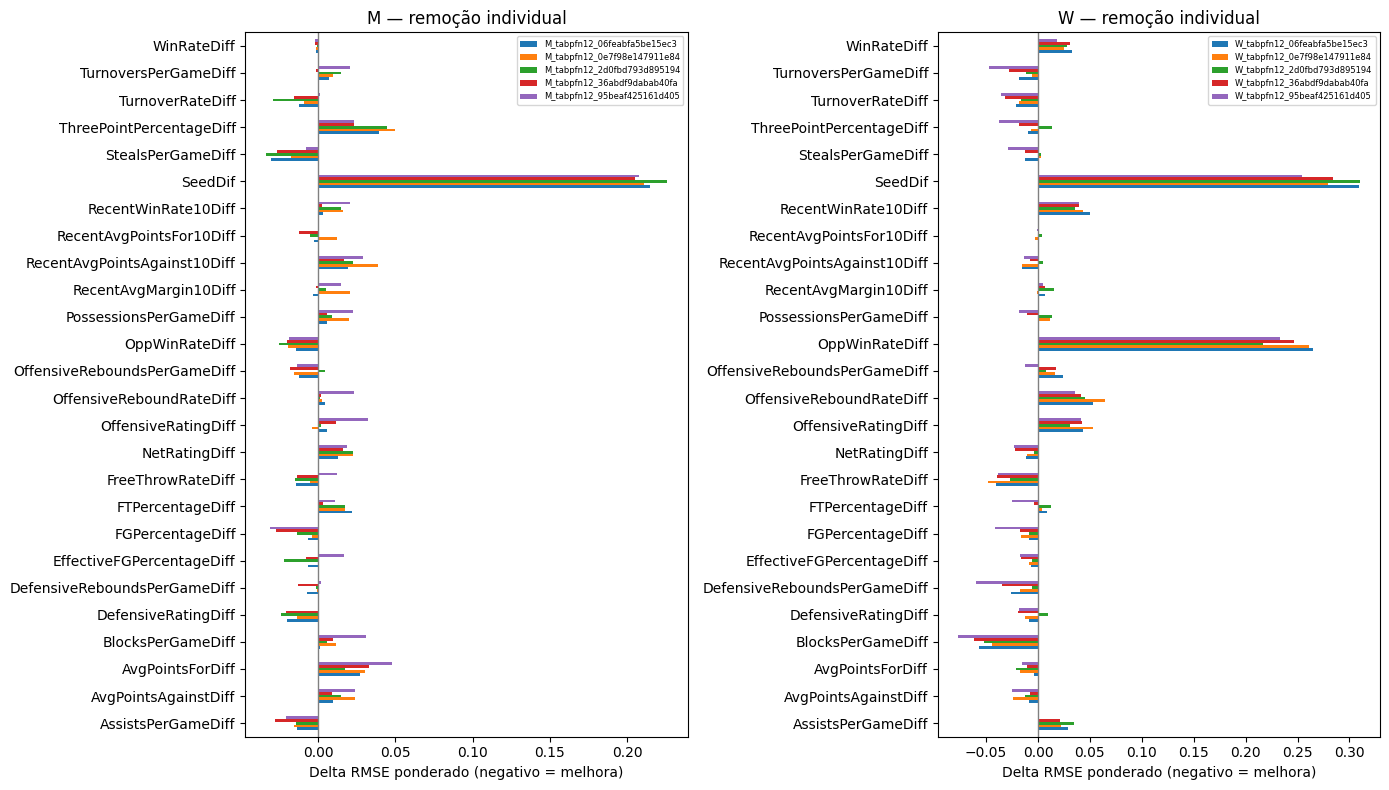

In [5]:
if RODAR_ANALISE_COMPLETA:
    individuais=exp.avaliar_individuais(avaliador)
    salvar_tabela('analise_individual.json',individuais)
    resumo_individual=exp.resumir_individuais(avaliador,individuais)
    display(resumo_individual)
    salvar_tabela('melhor_trial_por_remocao.json',resumo_individual)
    display(individuais.assign(Melhorou=individuais.Impacto.eq('melhorou')).groupby(
        ['Categoria','Configuracao']).agg(Testes=('FeatureRemovida','size'),Melhoraram=('Melhorou','sum')))
    colunas=['PosicaoImpacto','FeatureRemovida','NFeatures','RMSE_controle','RMSE_sem',
             'Delta_RMSE','LB_controle','LB_sem','Delta_LB','Impacto','status']
    for (cat,ident),grupo in individuais.groupby(['Categoria','Configuracao'],sort=False):
        display(HTML('<details><summary>'+escape(f'{cat} — {ident}: ranking das 26 remoções')+
            '</summary>'+grupo[colunas].to_html(index=False,escape=True)+'</details>'))
    fig,axes=plt.subplots(1,2,figsize=(14,8))
    for ax,cat in zip(axes,['M','W']):
        plot=individuais.loc[individuais.Categoria.eq(cat)].pivot(
            index='FeatureRemovida',columns='Configuracao',values='Delta_RMSE')
        plot.plot.barh(ax=ax)
        ax.axvline(0,color='gray',linewidth=1)
        ax.set(title=cat+' — remoção individual',xlabel='Delta RMSE ponderado (negativo = melhora)',ylabel='')
        ax.legend(fontsize=6)
    plt.tight_layout(); plt.show()
else:
    print('Análise completa desativada; habilite-a depois de conferir o piloto.')


## Eliminação conjunta de features e configuração

Depois de completar as remoções individuais, há uma trajetória para M e outra para W.
Em cada remoção candidata, os cinco trials são avaliados; o melhor conjunto/configuração
é aceito se superar a referência atual por MELHORA_MINIMA_RMSE. A configuração vencedora
pode mudar entre passos, mantendo seus próprios parâmetros fixos entre os três anos.

Uma rodada ou pool incompleto por orçamento não aceita uma remoção parcial. Falhas
são registradas e só trials válidos concorrem. O histórico aponta mudanças de configuração.
Quando ela muda, o ganho corresponde à escolha conjunta de modelo/features; não é uma
estimativa isolada do efeito da feature. O relatório individual pareado permanece disponível.

In [6]:
progressivas=[]
if RODAR_PROGRESSIVA:
    for categoria in ['M','W']:
        progressivas.append(exp.selecao_progressiva(avaliador,categoria,ativar=True,
            max_removidas=MAX_FEATURES_REMOVIDAS,min_features=MIN_FEATURES,melhora_minima=MELHORA_MINIMA_RMSE))
    resumo=pd.DataFrame([{k:r[k] for k in ['Categoria','Configuracao','NFeatures','NRemovidas',
        'RMSE_pond','LB_pond','Motivo']} for r in progressivas])
    display(resumo)
    for r in progressivas:
        display(HTML('<details><summary>'+escape(f"{r['Categoria']} — {r['Configuracao']}: {r['NFeatures']} features finais")+
            '</summary><p><strong>Mantidas:</strong> '+escape(', '.join(r['Features']))+
            '</p><p><strong>Removidas:</strong> '+escape(', '.join(r['Removidas']) or 'Nenhuma')+'</p></details>'))
        historia=pd.DataFrame([{k:v for k,v in rodada.items() if k not in ['Testes','FeaturesAntes']}
            for rodada in r['Rodadas']])
        if not historia.empty:
            display(historia)
    comum.salvar_json(CHECKPOINTS/'progressivas_resumo.json',progressivas)
else:
    print('Seleção progressiva desativada.')
display(avaliador.contagem())


,Categoria,Configuracao,NFeatures,NRemovidas,RMSE_pond,LB_pond,Motivo
0,M,M_tabpfn12_0e7f98e147911e84,22,4,12.004557,0.071774,orcamento_rodada_incompleta
1,W,W_tabpfn12_2d0fbd793d895194,24,2,12.268132,0.049459,sem_melhora_minima


,Rodada,Referencia,ConfiguracaoAntes,NFeaturesAntes,RMSE_antes,LB_antes,Aceita,Removida,ConfiguracaoDepois,MudouConfiguracao,MelhoraRMSE
0,1,M_tabpfn12_36abdf9dabab40fa__ffc601c53ba08bbed,M_tabpfn12_36abdf9dabab40fa,26,12.114713,0.073605,True,AssistsPerGameDiff,M_tabpfn12_36abdf9dabab40fa,False,0.027744
1,2,M_tabpfn12_36abdf9dabab40fa__f55def85d5d43f8a0,M_tabpfn12_36abdf9dabab40fa,25,12.086968,0.073129,True,OppWinRateDiff,M_tabpfn12_95beaf425161d405,True,0.037508
2,3,M_tabpfn12_95beaf425161d405__fada023e243608853,M_tabpfn12_95beaf425161d405,24,12.049460,0.073341,True,StealsPerGameDiff,M_tabpfn12_36abdf9dabab40fa,True,0.022303
3,4,M_tabpfn12_36abdf9dabab40fa__f4cc9e9d48fe08c9f,M_tabpfn12_36abdf9dabab40fa,23,12.027157,0.073326,True,DefensiveReboundsPerGameDiff,M_tabpfn12_0e7f98e147911e84,True,0.022601
4,5,M_tabpfn12_0e7f98e147911e84__f08a49602b4c8efab,M_tabpfn12_0e7f98e147911e84,22,12.004557,0.071774,False,None,NaN,NaN,NaN


,Rodada,Referencia,ConfiguracaoAntes,NFeaturesAntes,RMSE_antes,LB_antes,Aceita,Removida,ConfiguracaoDepois,MudouConfiguracao,MelhoraRMSE
0,1,W_tabpfn12_2d0fbd793d895194__ffc601c53ba08bbed,W_tabpfn12_2d0fbd793d895194,26,12.390296,0.050894,True,BlocksPerGameDiff,W_tabpfn12_2d0fbd793d895194,False,0.051804
1,2,W_tabpfn12_2d0fbd793d895194__f6dfe19bc23127c40,W_tabpfn12_2d0fbd793d895194,25,12.338493,0.049900,True,AvgPointsAgainstDiff,W_tabpfn12_2d0fbd793d895194,False,0.070361
2,3,W_tabpfn12_2d0fbd793d895194__ff4862199c7c40cdf,W_tabpfn12_2d0fbd793d895194,24,12.268132,0.049459,False,None,NaN,NaN,NaN


,Categoria,Configuracao,AvaliacoesUsadas,Limite
0,M,M_tabpfn12_06feabfa5be15ec3,100,100
1,M,M_tabpfn12_95beaf425161d405,100,100
2,M,M_tabpfn12_36abdf9dabab40fa,100,100
3,M,M_tabpfn12_0e7f98e147911e84,100,100
4,M,M_tabpfn12_2d0fbd793d895194,100,100
5,W,W_tabpfn12_06feabfa5be15ec3,75,100
6,W,W_tabpfn12_95beaf425161d405,75,100
7,W,W_tabpfn12_36abdf9dabab40fa,75,100
8,W,W_tabpfn12_0e7f98e147911e84,75,100
9,W,W_tabpfn12_2d0fbd793d895194,75,100


## Ranking final e comparação com o controle

Todas as combinações configuração + subconjunto com três cortes válidos concorrem,
incluindo os controles. O Top 5 pode conter a mesma configuração com subconjuntos
diferentes. Isso é distinto da trajetória aceita pela eliminação regressiva:
esta respeita a melhora mínima e só decide em rodadas completas.

O ranking contém apenas candidatos efetivamente avaliados no contexto atual.
Resultados parciais do piloto/orçamento não representam a busca completa.


### Exp. 14 — Top 5 por RMSE ponderado, entre as combinações avaliadas

**Masculino (M)**

,Posicao,Configuracao,NFeatures,NRemovidas,RMSE_pond,LB_pond,Delta_RMSE_pond,Delta_LB_pond
0,1,M_tabpfn12_0e7f98e147911e84,22,4,12.004557,0.071774,-0.132218,-0.001677
1,2,M_tabpfn12_06feabfa5be15ec3,22,4,12.004692,0.071955,-0.128911,-0.001666
2,3,M_tabpfn12_36abdf9dabab40fa,22,4,12.007912,0.072236,-0.106801,-0.001369
3,4,M_tabpfn12_95beaf425161d405,22,4,12.017925,0.071963,-0.103224,-0.001465
4,5,M_tabpfn12_36abdf9dabab40fa,22,4,12.022241,0.072848,-0.092472,-0.000757


**Feminino (W)**

,Posicao,Configuracao,NFeatures,NRemovidas,RMSE_pond,LB_pond,Delta_RMSE_pond,Delta_LB_pond
0,1,W_tabpfn12_2d0fbd793d895194,24,2,12.268132,0.049459,-0.122165,-0.001436
1,2,W_tabpfn12_36abdf9dabab40fa,24,2,12.274785,0.049208,-0.134984,-0.001074
2,3,W_tabpfn12_06feabfa5be15ec3,24,2,12.279359,0.049247,-0.124297,-0.001305
3,4,W_tabpfn12_2d0fbd793d895194,23,3,12.279661,0.049989,-0.110635,-0.000906
4,5,W_tabpfn12_95beaf425161d405,23,3,12.281290,0.049885,-0.140810,-0.000656


,Categoria,Posicao,Configuracao,NFeatures,RMSE_2023,RMSE_2024,RMSE_2025,RMSE_pond,RMSE_media,LB_2023,LB_2024,LB_2025,LB_pond
0,M,1,M_tabpfn12_0e7f98e147911e84,22,11.740190,12.938026,11.331049,12.004557,12.003088,0.079553,0.076702,0.061443,0.071774
1,M,2,M_tabpfn12_06feabfa5be15ec3,22,11.737131,12.928938,11.342126,12.004692,12.002731,0.079646,0.076983,0.061596,0.071955
2,M,3,M_tabpfn12_36abdf9dabab40fa,22,11.775090,12.917385,11.333445,12.007912,12.008640,0.080187,0.077315,0.061639,0.072236
3,M,4,M_tabpfn12_95beaf425161d405,22,11.707651,12.962293,11.368173,12.017925,12.012705,0.079223,0.076934,0.061976,0.071963
4,M,5,M_tabpfn12_36abdf9dabab40fa,22,11.947795,12.946939,11.216666,12.022241,12.037134,0.083674,0.077421,0.060600,0.072848
505,W,1,W_tabpfn12_2d0fbd793d895194,24,11.921731,10.485340,14.183001,12.268132,12.196691,0.065433,0.043789,0.042940,0.049459
506,W,2,W_tabpfn12_36abdf9dabab40fa,24,12.028065,10.427454,14.176115,12.274785,12.210544,0.065835,0.042977,0.042729,0.049208
507,W,3,W_tabpfn12_06feabfa5be15ec3,24,12.050682,10.439321,14.160581,12.279359,12.216861,0.065703,0.043592,0.042360,0.049247
508,W,4,W_tabpfn12_2d0fbd793d895194,23,11.917673,10.464680,14.235994,12.279661,12.206116,0.066121,0.043067,0.044518,0.049989
509,W,5,W_tabpfn12_95beaf425161d405,23,11.930097,10.427157,14.266088,12.281290,12.207781,0.066780,0.042279,0.044488,0.049885


... (3 outputs left out)

**Top 2 — M: 22 features | W: 24 features**

**Top 3 — M: 22 features | W: 24 features**

**Top 4 — M: 22 features | W: 23 features**

**Top 5 — M: 22 features | W: 23 features**

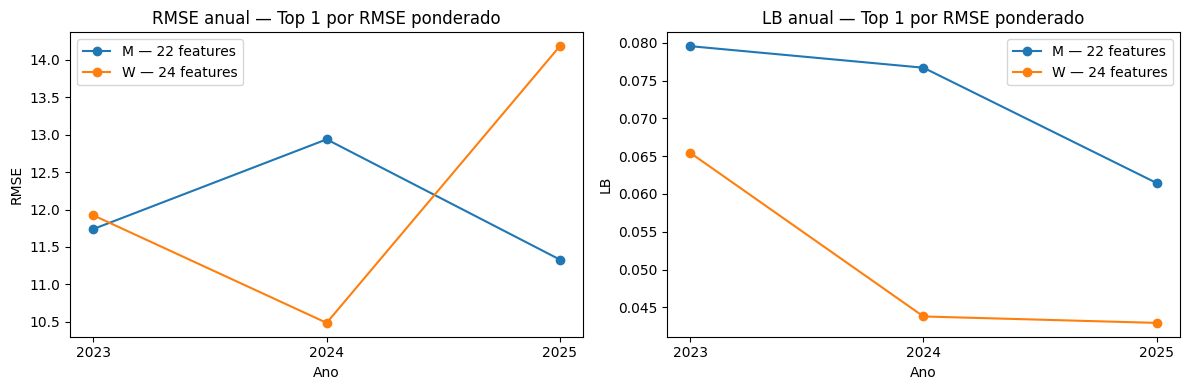

In [7]:
ranking=avaliador.ranking()
salvar_tabela('ranking.json',ranking)
mostrar_top(ranking,f'Exp. 14 — Top {TOP_K} por RMSE ponderado, entre as combinações avaliadas')
if not ranking.empty:
    top=ranking.loc[ranking.Posicao.le(TOP_K)]
    anuais=['Categoria','Posicao','Configuracao','NFeatures','RMSE_2023','RMSE_2024','RMSE_2025',
            'RMSE_pond','RMSE_media','LB_2023','LB_2024','LB_2025','LB_pond']
    display(top[anuais])
    controles=ranking.loc[ranking.NFeatures.eq(26)].copy()
    display(controles[['Categoria','Configuracao','NFeatures','RMSE_pond','LB_pond']])
    print('Delta_RMSE_pond do ranking é pareado com o controle de 26 features da mesma configuração.')
    comuns=exp.comparar_categorias(ranking,top_k=TOP_K)
    for r in comuns.to_dict('records'):
        display(Markdown(f"**Top {r['Posicao']} — M: {r['NFeaturesM']} features | W: {r['NFeaturesW']} features**"))
        for col in ['MantidasAmbas','RemovidasSomenteM','RemovidasSomenteW','RemovidasAmbas']:
            display(HTML('<details><summary>'+escape(col+': '+str(len(r[col])))+
                '</summary><p>'+escape(', '.join(r[col]) or 'Nenhuma')+'</p></details>'))
    salvar_tabela('features_por_categoria.json',comuns)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,metrica in zip(axes,['RMSE','LB']):
        for r in top.loc[top.Posicao.eq(1)].to_dict('records'):
            ax.plot(ANOS,[r[f'{metrica}_{ano}'] for ano in ANOS],marker='o',
                label=f"{r['Categoria']} — {r['NFeatures']} features")
        ax.set(title=metrica+' anual — Top 1 por RMSE ponderado',xticks=ANOS,xlabel='Ano',ylabel=metrica)
        ax.legend()
    plt.tight_layout(); plt.show()

## Checkpoints, tempo e cobertura

O estado salva todos os subconjuntos e os três cortes, incluindo falhas, tempos,
recursos e etapas. Os arquivos de cada corte também preservam previsões e parâmetros.
Dados/versões/protocolo diferentes criam outro contexto; checkpoints antigos ficam
preservados. REPETIR_FALHAS=True repete somente falhas, sem refazer sucessos.


In [8]:
avaliacoes=list(avaliador.estado['avaliacoes'].values())
if avaliacoes:
    cobertura=pd.DataFrame(avaliacoes).groupby(['Categoria','Configuracao','status']).size().rename('Subconjuntos')
    display(cobertura)
    recursos=pd.DataFrame([{'Categoria':r['Categoria'],'Configuracao':r['Configuracao'],'Avaliacao':r['Candidato'],
        'NFeatures':r['NFeatures'],'Season':c['Season'],'status':c['status'],'erro':c.get('erro'),
        'segundos':0.,**(c.get('recursos') or {})} for r in avaliacoes for c in r.get('Cortes',[])])
    if not recursos.empty:
        display(recursos.groupby(['Categoria','Configuracao']).agg(Cortes=('Season','size'),
            Segundos=('segundos','sum')))
        salvar_tabela('recursos.json',recursos)
    print('Tempos reutilizados são históricos, não o custo desta execução.')
registro={'features_iniciais':FEATURES,'anos':ANOS,'seed':SEED,'n_folds':5,'top_k':TOP_K,
    'pesos':REFERENCIAS.to_dict('records'),'versoes':comum.versoes(),'fontes':manifesto['fontes'],
    'candidatos':catalogo,'busca':manifesto['busca'],'metodo_progressiva':'conjunta por categoria','estado':str(avaliador.path_estado),'criterio':'RMSE ponderado',
    'piloto':{'ativo':RODAR_PILOTO,'features':PILOTO_FEATURES,'configuracoes_por_categoria':PILOTO_CONFIGURACOES_POR_CATEGORIA},
    'analise_completa':RODAR_ANALISE_COMPLETA,'progressiva':RODAR_PROGRESSIVA,
    'limites':{'avaliacoes_por_configuracao':MAX_AVALIACOES_POR_CONFIGURACAO,'max_removidas':MAX_FEATURES_REMOVIDAS,
        'min_features':MIN_FEATURES,'melhora_minima':MELHORA_MINIMA_RMSE}}
comum.salvar_json(CHECKPOINTS/'registro.json',registro)


Categoria  Configuracao                 status
M          M_tabpfn12_06feabfa5be15ec3  ok        101
           M_tabpfn12_0e7f98e147911e84  ok        101
           M_tabpfn12_2d0fbd793d895194  ok        101
           M_tabpfn12_36abdf9dabab40fa  ok        101
           M_tabpfn12_95beaf425161d405  ok        101
W          W_tabpfn12_06feabfa5be15ec3  ok         76
           W_tabpfn12_0e7f98e147911e84  ok         76
           W_tabpfn12_2d0fbd793d895194  ok         76
           W_tabpfn12_36abdf9dabab40fa  ok         76
           W_tabpfn12_95beaf425161d405  ok         76
Name: Subconjuntos, dtype: int64

Cortes     Segundos
Categoria Configuracao                                    
M         M_tabpfn12_06feabfa5be15ec3     303   825.953332
          M_tabpfn12_0e7f98e147911e84     303  1565.113602
          M_tabpfn12_2d0fbd793d895194     303   464.699173
          M_tabpfn12_36abdf9dabab40fa     303   289.342218
          M_tabpfn12_95beaf425161d405     303   201.228214
W         W_tabpfn12_06feabfa5be15ec3     228   442.941377
          W_tabpfn12_0e7f98e147911e84     228   834.249116
          W_tabpfn12_2d0fbd793d895194     228   273.521241
          W_tabpfn12_36abdf9dabab40fa     228   172.312099
          W_tabpfn12_95beaf425161d405     228   130.161099

Tempos reutilizados são históricos, não o custo desta execução.


## Submissões opcionais

Somente quando GERAR_SUBMISSIONS=True. Retreinar com Season < 2026 e o subconjunto
próprio de cada combinação selecionada. Combinar posições iguais de M/W, do Top 1 ao Top 5.
Margens brutas, fallback zero, IDs e ordem do sample preservados. Nenhum envio ao Kaggle. Os cinco CSVs vão para `submissions/exp14_busca_independente/`, preservando os anteriores.


In [9]:
if GERAR_SUBMISSIONS:
    submissions=exp.gerar_submissions(avaliador,ranking,confrontos,sample,destino=SUBMISSIONS,top_k=TOP_K)
    display(pd.DataFrame(submissions['submissions'])[
        ['Arquivo','NFeaturesM','NFeaturesW','ConfiguracaoM','ConfiguracaoW','Linhas','IdenticaA']])
    registro['submissions']=submissions
    comum.salvar_json(CHECKPOINTS/'registro.json',registro)
else:
    print('Treino final e geração de CSVs desativados. Habilite GERAR_SUBMISSIONS quando concluir a seleção.')


,Arquivo,NFeaturesM,NFeaturesW,ConfiguracaoM,ConfiguracaoW,Linhas,IdenticaA
0,submission_exp14_tabpfn_rmse_top1_2026.csv,22,24,M_tabpfn12_0e7f98e147911e84,W_tabpfn12_2d0fbd793d895194,132133,None
1,submission_exp14_tabpfn_rmse_top2_2026.csv,22,24,M_tabpfn12_06feabfa5be15ec3,W_tabpfn12_36abdf9dabab40fa,132133,None
2,submission_exp14_tabpfn_rmse_top3_2026.csv,22,24,M_tabpfn12_36abdf9dabab40fa,W_tabpfn12_06feabfa5be15ec3,132133,None
3,submission_exp14_tabpfn_rmse_top4_2026.csv,22,23,M_tabpfn12_95beaf425161d405,W_tabpfn12_2d0fbd793d895194,132133,None
4,submission_exp14_tabpfn_rmse_top5_2026.csv,22,23,M_tabpfn12_36abdf9dabab40fa,W_tabpfn12_95beaf425161d405,132133,None
